In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
import pandas as pd

df = pd.read_csv("cities_magicbricks_rental_prices.csv")


In [15]:
df

,house_type,locality,city,area,beds,bathrooms,balconies,furnishing,area_rate,rent
0,"2 BHK Flat for Rent in Oberoi Woods, Goregaon ...",Goregaon East,Mumbai,897.0,2,2,0,Semi-Furnished,134.0,120000.0
1,"1 BHK Flat for Rent in Sapphire Lakeside, Powa...",Powai,Mumbai,490.0,1,1,0,Semi-Furnished,82.0,40000.0
2,1 BHK House for Rent in Mundhwa Pune,Mundhwa,Pune,550.0,1,1,0,Unfurnished,22.0,12000.0
3,"2 BHK Flat for Rent in Hingna, Nagpur",Hingna,Nagpur,1000.0,2,2,0,Unfurnished,8.0,8000.0
4,1 BHK Flat for Rent in Unique Star Harsh Vihar...,Mira Road,Mumbai,595.0,1,1,0,Unfurnished,25.0,15000.0
...,...,...,...,...,...,...,...,...,...,...
7686,"3 BHK Flat for Rent in Saket, New Delhi",Saket,New Delhi,1750.0,3,3,0,Furnished,27.0,47000.0
7687,"2 BHK Flat for Rent in Phase 7 JP Nagar, Banga...",Phase 7 JP Nagar,Bangalore,1050.0,2,2,2,Semi-Furnished,27.0,28000.0
7688,"2 BHK Flat for Rent in Malpani Vivanta, Balewa...",Balewadi,Pune,734.0,2,2,2,Unfurnished,48.0,35000.0
7689,"1 BHK Flat for Rent in Shalimar bagh, New Delhi",Shalimar bagh,New Delhi,400.0,1,1,0,Semi-Furnished,38.0,15000.0


### Data cleaning and preprocessing


In [22]:
# TOP Value
df.head()


,house_type,locality,city,area,beds,bathrooms,balconies,furnishing,area_rate,rent
0,"2 BHK Flat for Rent in Oberoi Woods, Goregaon ...",Goregaon East,Mumbai,897.0,2,2,0,Semi-Furnished,134.0,120000.0
1,"1 BHK Flat for Rent in Sapphire Lakeside, Powa...",Powai,Mumbai,490.0,1,1,0,Semi-Furnished,82.0,40000.0
2,1 BHK House for Rent in Mundhwa Pune,Mundhwa,Pune,550.0,1,1,0,Unfurnished,22.0,12000.0
3,"2 BHK Flat for Rent in Hingna, Nagpur",Hingna,Nagpur,1000.0,2,2,0,Unfurnished,8.0,8000.0
4,1 BHK Flat for Rent in Unique Star Harsh Vihar...,Mira Road,Mumbai,595.0,1,1,0,Unfurnished,25.0,15000.0


In [24]:
# Top Taill Values
df.tail()


,house_type,locality,city,area,beds,bathrooms,balconies,furnishing,area_rate,rent
7686,"3 BHK Flat for Rent in Saket, New Delhi",Saket,New Delhi,1750.0,3,3,0,Furnished,27.0,47000.0
7687,"2 BHK Flat for Rent in Phase 7 JP Nagar, Banga...",Phase 7 JP Nagar,Bangalore,1050.0,2,2,2,Semi-Furnished,27.0,28000.0
7688,"2 BHK Flat for Rent in Malpani Vivanta, Balewa...",Balewadi,Pune,734.0,2,2,2,Unfurnished,48.0,35000.0
7689,"1 BHK Flat for Rent in Shalimar bagh, New Delhi",Shalimar bagh,New Delhi,400.0,1,1,0,Semi-Furnished,38.0,15000.0
7690,"2 BHK Flat for Rent in Govindpura, Dooravani N...",Govindpura,Bangalore,450.0,2,1,0,Unfurnished,22.0,10000.0


In [26]:
# check the  Columns
df.columns

Index(['house_type', 'locality', 'city', 'area', 'beds', 'bathrooms',
       'balconies', 'furnishing', 'area_rate', 'rent'],
      dtype='object')

In [28]:
# Check data types
df.dtypes

house_type     object
locality       object
city           object
area          float64
beds            int64
bathrooms       int64
balconies       int64
furnishing     object
area_rate     float64
rent          float64
dtype: object

In [464]:
# 
df.describe()

,area,beds,bathrooms,balconies,area_rate,rent
count,7691.000000,7691.000000,7691.000000,7691.000000,7691.000000,7.691000e+03
mean,1106.354180,2.208685,2.137043,0.817319,47.619989,5.479508e+04
std,1197.426843,0.993481,1.027677,1.243361,68.989657,9.742006e+04
min,2.000000,1.000000,0.000000,0.000000,2.000000,1.000000e+03
25%,600.000000,1.000000,1.000000,0.000000,21.000000,1.500000e+04
50%,900.000000,2.000000,2.000000,0.000000,31.000000,2.800000e+04
75%,1300.000000,3.000000,3.000000,2.000000,54.000000,5.700000e+04
max,70000.000000,10.000000,10.000000,10.000000,2586.000000,2.700000e+06


In [30]:
# check is null values
df.isnull().sum()


house_type    0
locality      0
city          0
area          0
beds          0
bathrooms     0
balconies     0
furnishing    0
area_rate     0
rent          0
dtype: int64

In [32]:

df.duplicated().sum()

0

In [17]:
# fillter data 
def get_type(x):
    x = str(x).lower()
    if "flat" in x or "apartment" in x:
        return "Apartment"
    elif "house" in x:
        return "House"
    else:
        return "Other"

df['property_type'] = df['house_type'].apply(get_type)

In [38]:
df

,house_type,locality,city,area,beds,bathrooms,balconies,furnishing,area_rate,rent,property_type
0,"2 BHK Flat for Rent in Oberoi Woods, Goregaon ...",Goregaon East,Mumbai,897.0,2,2,0,Semi-Furnished,134.0,120000.0,Apartment
1,"1 BHK Flat for Rent in Sapphire Lakeside, Powa...",Powai,Mumbai,490.0,1,1,0,Semi-Furnished,82.0,40000.0,Apartment
2,1 BHK House for Rent in Mundhwa Pune,Mundhwa,Pune,550.0,1,1,0,Unfurnished,22.0,12000.0,House
3,"2 BHK Flat for Rent in Hingna, Nagpur",Hingna,Nagpur,1000.0,2,2,0,Unfurnished,8.0,8000.0,Apartment
4,1 BHK Flat for Rent in Unique Star Harsh Vihar...,Mira Road,Mumbai,595.0,1,1,0,Unfurnished,25.0,15000.0,Apartment
...,...,...,...,...,...,...,...,...,...,...,...
7686,"3 BHK Flat for Rent in Saket, New Delhi",Saket,New Delhi,1750.0,3,3,0,Furnished,27.0,47000.0,Apartment
7687,"2 BHK Flat for Rent in Phase 7 JP Nagar, Banga...",Phase 7 JP Nagar,Bangalore,1050.0,2,2,2,Semi-Furnished,27.0,28000.0,Apartment
7688,"2 BHK Flat for Rent in Malpani Vivanta, Balewa...",Balewadi,Pune,734.0,2,2,2,Unfurnished,48.0,35000.0,Apartment
7689,"1 BHK Flat for Rent in Shalimar bagh, New Delhi",Shalimar bagh,New Delhi,400.0,1,1,0,Semi-Furnished,38.0,15000.0,Apartment


In [19]:
# Fillter Numric columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
print(numeric_cols)

Index(['area', 'beds', 'bathrooms', 'balconies', 'area_rate', 'rent'], dtype='object')


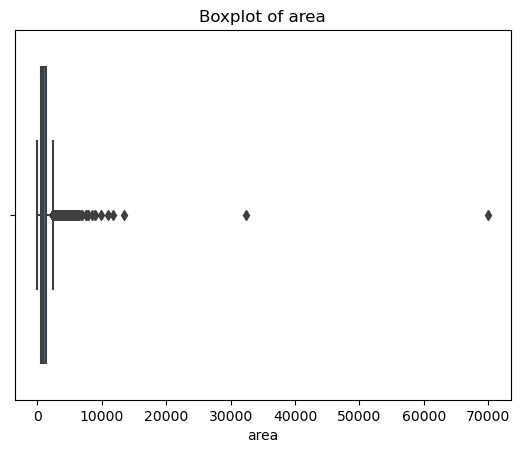

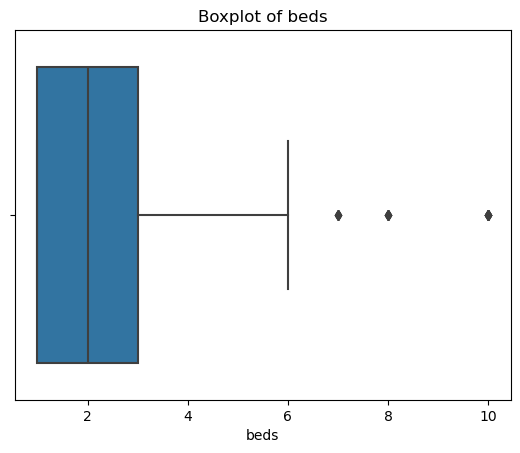

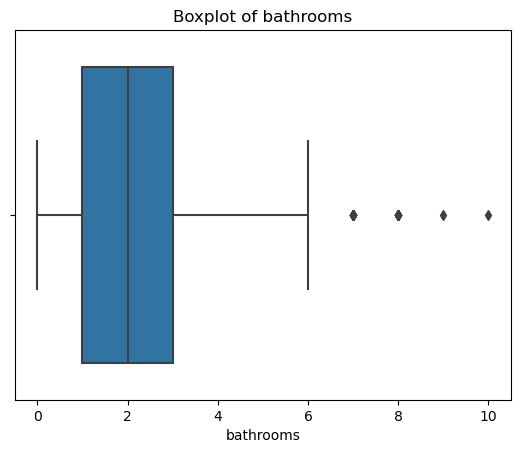

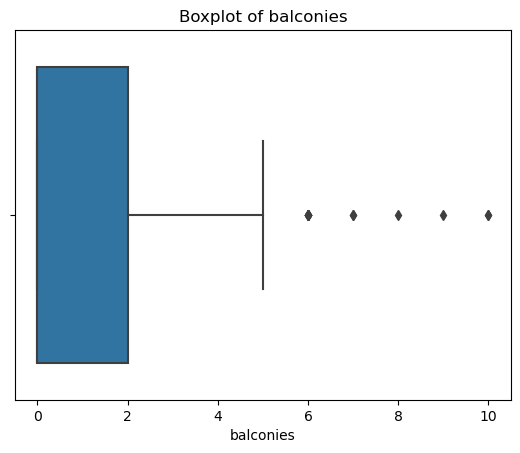

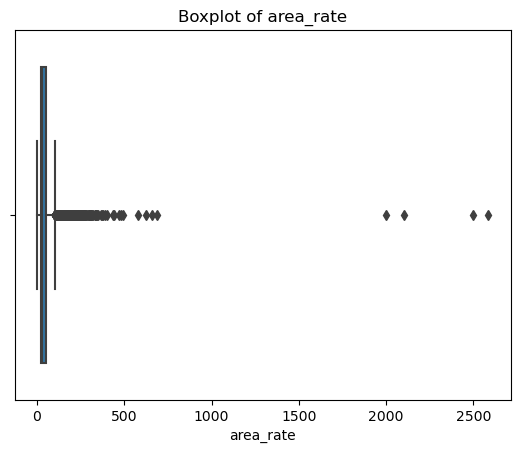

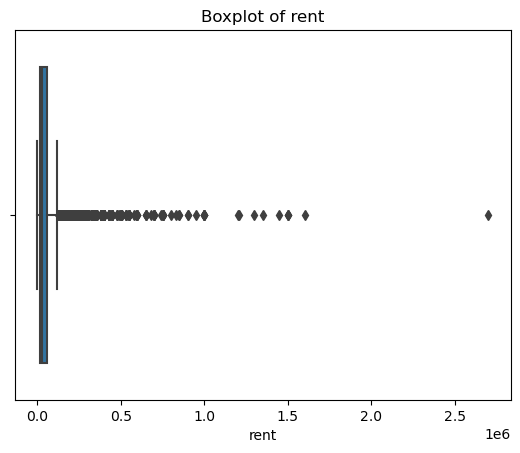

In [42]:
# Plot the box check outlier
for col in numeric_cols:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

### EDA : 

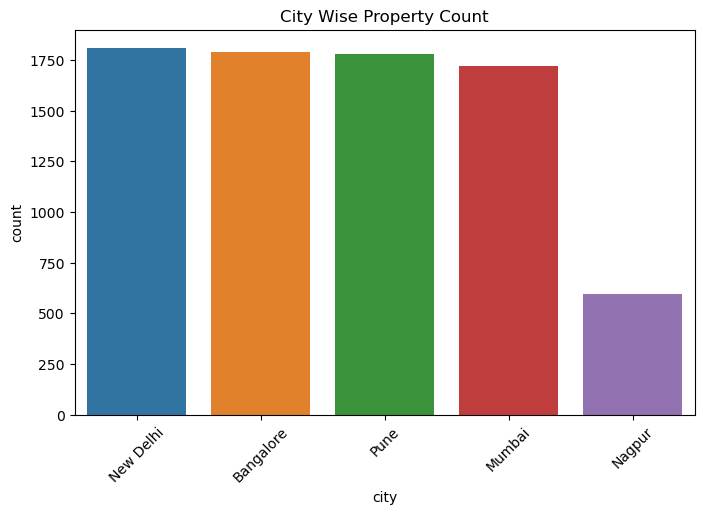

In [28]:
# -------------------------------
# 1. City Wise Properties Count
# -------------------------------
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="city", order=df["city"].value_counts().index)
plt.title("City Wise Property Count")
plt.xticks(rotation=45)
plt.show()

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


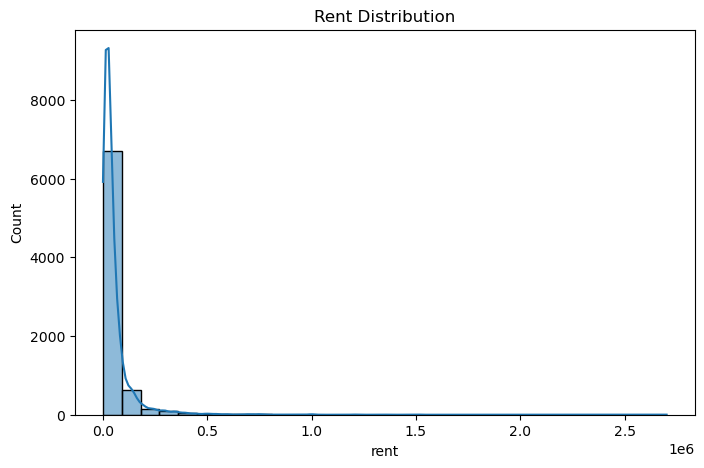

In [32]:
# -------------------------------
# 2. Rent Distribution Histogram
# -------------------------------
plt.figure(figsize=(8,5))
sns.histplot(df["rent"], bins=30, kde=True)
plt.title("Rent Distribution")
plt.show()


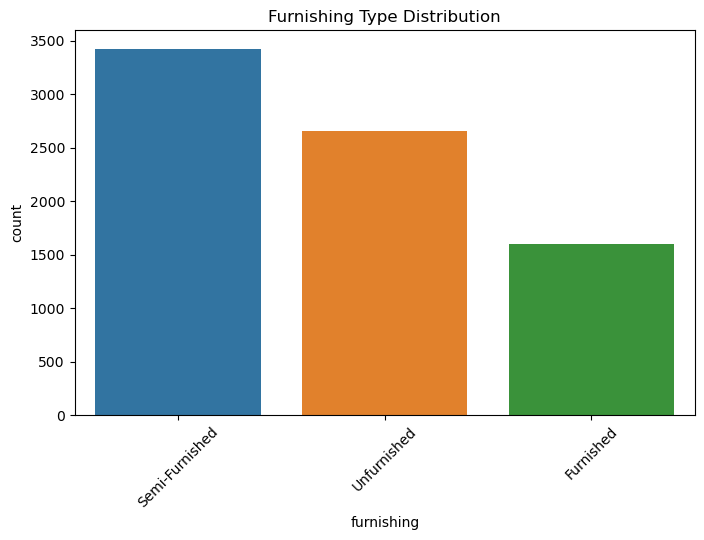

In [34]:
# -------------------------------
# 3. Furnishing Type Count
# -------------------------------
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="furnishing", order=df["furnishing"].value_counts().index)
plt.title("Furnishing Type Distribution")
plt.xticks(rotation=45)
plt.show()

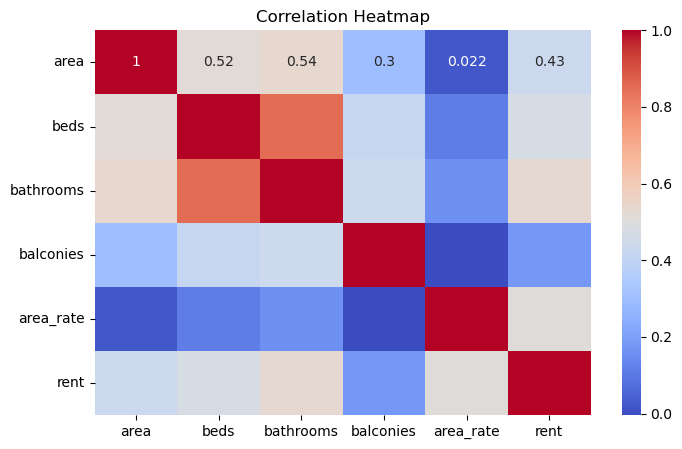

In [36]:
# -------------------------------
# 4. Correlation Heatmap
# -------------------------------
plt.figure(figsize=(8,5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

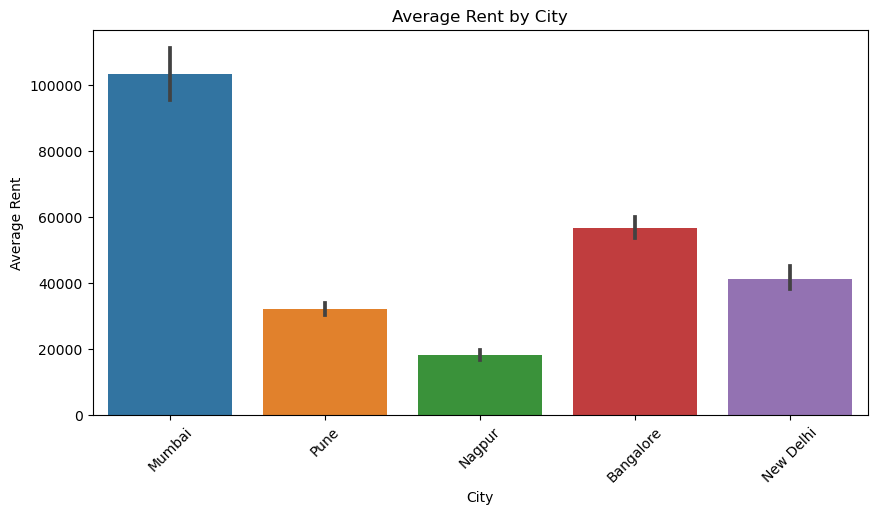

In [38]:
# 5. Average Rent by City
plt.figure(figsize=(10,5))
sns.barplot(data=df, x="city", y="rent", estimator="mean")
plt.title("Average Rent by City")
plt.xlabel("City")
plt.ylabel("Average Rent")
plt.xticks(rotation=45)
plt.show()

In [21]:
# Features & Target
X = df.drop('rent', axis=1)
y = df['rent']

In [23]:
# Encoding :-
X = pd.get_dummies(X)

In [25]:
# Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
# model LinearRegression:-

In [54]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

In [56]:
# Model train karo
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [60]:
# Prediction karo
y_pred = lr_model.predict(X_test)

In [62]:
# Performance check karo
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.6901286175935275
MAE: 22965.419471652207
RMSE: 48189.330663910245


In [ ]:
#Model 2: Decision Tree Regressor

In [64]:
from sklearn.tree import DecisionTreeRegressor

In [68]:
# Model create karo
dt_model = DecisionTreeRegressor(random_state=42)

In [70]:
# Model train 
dt_model.fit(X_train, y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_l

In [72]:
# Prediction 
y_pred_dt = dt_model.predict(X_test)


In [74]:
# Performance check
print("Decision Tree R2 Score:", r2_score(y_test, y_pred_dt))
print("Decision Tree MAE:", mean_absolute_error(y_test, y_pred_dt))
print("Decision Tree RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_dt)))

Decision Tree R2 Score: 0.9291168184812852
Decision Tree MAE: 3483.2423651721897
Decision Tree RMSE: 23047.92119734811


In [ ]:
#RandomForestRegressor

In [ ]:
from sklearn.ensemble import RandomForestRegressor


In [144]:
# Model create karo
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [146]:
# Model train karo
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [147]:
# Prediction karo
y_pred_rf = rf_model.predict(X_test)

In [150]:
# Performance check karo
print("Random Forest R2 Score:", r2_score(y_test, y_pred_rf))
print("Random Forest MAE:", mean_absolute_error(y_test, y_pred_rf))
print("Random Forest RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))

Random Forest R2 Score: 0.9693266642818957
Random Forest MAE: 2165.195341130604
Random Forest RMSE: 15161.447390662177


In [106]:
#Model Train (Random Forest 🔥)
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [ ]:
# Predtion
y_pred = model.predict(X_test)   # ✅ CORRECT

In [63]:
# Evaluation (IMPORTANT)
from sklearn.metrics import r2_score, mean_absolute_error

print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))

R2 Score: 0.9706465150448492
MAE: 2099.2117348927873


In [65]:
# Model save
import joblib

joblib.dump(model, "rent_model.pkl")

['rent_model.pkl']

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Model create karo
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Model train karo
gb_model.fit(X_train, y_train)

# Prediction karo
y_pred_gb = gb_model.predict(X_test)

# Performance check karo
print("Gradient Boosting R2 Score:", r2_score(y_test, y_pred_gb))
print("Gradient Boosting MAE:", mean_absolute_error(y_test, y_pred_gb))
print("Gradient Boosting RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_gb)))

In [116]:
# GradientBoostingRegressor:-

In [118]:
from sklearn.ensemble import GradientBoostingRegressor

In [120]:
# Model create 
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)


In [122]:
# Model train 
gb_model.fit(X_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft

In [124]:
# Prediction karo
y_pred_gb = gb_model.predict(X_test)


In [126]:
# Performance check karo
print("Gradient Boosting R2 Score:", r2_score(y_test, y_pred_gb))
print("Gradient Boosting MAE:", mean_absolute_error(y_test, y_pred_gb))
print("Gradient Boosting RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_gb)))

Gradient Boosting R2 Score: 0.978183232771995
Gradient Boosting MAE: 5952.639259831205
Gradient Boosting RMSE: 12786.60820940577


In [128]:
#XGBoost Regressor

In [130]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [29]:
from xgboost import XGBRegressor

In [31]:
# Model create karo
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

In [33]:
# Model train karo
xgb_model.fit(X_train, y_train)


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [34]:
# Prediction karo
y_pred_xgb = xgb_model.predict(X_test)


In [35]:
# Performance check karo
print("XGBoost R2 Score:", r2_score(y_test, y_pred_xgb))
print("XGBoost MAE:", mean_absolute_error(y_test, y_pred_xgb))
print("XGBoost RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_xgb)))

XGBoost R2 Score: 0.9707032723028712
XGBoost MAE: 3188.0158550220312
XGBoost RMSE: 14817.321923449417


In [ ]:
#Cross-validation — pehle Random Forest

In [152]:
from sklearn.model_selection import cross_val_score
import numpy as np

rf_cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("Random Forest CV Scores:", rf_cv_scores)
print("Mean CV R2:", rf_cv_scores.mean())
print("Standard Deviation:", rf_cv_scores.std())

Random Forest CV Scores: [0.96211521 0.75966825 0.93216301 0.99235191 0.97087511]
Mean CV R2: 0.9234346975085312
Standard Deviation: 0.08413321566657964


In [ ]:
#Gradient Boosting cross-validation

In [154]:
from sklearn.model_selection import cross_val_score

gb_cv_scores = cross_val_score(
    gb_model,
    X,
    y,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("Gradient Boosting CV Scores:", gb_cv_scores)
print("Mean CV R2:", gb_cv_scores.mean())
print("Standard Deviation:", gb_cv_scores.std())

Gradient Boosting CV Scores: [0.96018275 0.80561196 0.93964481 0.98646058 0.97219872]
Mean CV R2: 0.9328197642644565
Standard Deviation: 0.06542962711253085


In [158]:
#xgb_cross-validation

In [156]:
xgb_cv_scores = cross_val_score(
    xgb_model,
    X,
    y,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("XGBoost CV Scores:", xgb_cv_scores)
print("Mean CV R2:", xgb_cv_scores.mean())
print("Standard Deviation:", xgb_cv_scores.std())

XGBoost CV Scores: [0.96199931 0.82623669 0.93454375 0.98591963 0.97745284]
Mean CV R2: 0.9372304416977404
Standard Deviation: 0.05818729455029248


In [ ]:
#Dono models ka test R² aur MAE verify

In [160]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

models = {
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

for name, predictions in models.items():
    print(f"\n{name}")
    print("R2 Score:", r2_score(y_test, predictions))
    print("MAE:", mean_absolute_error(y_test, predictions))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))


Random Forest
R2 Score: 0.9693266642818957
MAE: 2165.195341130604
RMSE: 15161.447390662177

XGBoost
R2 Score: 0.9707032723028712
MAE: 3188.0158550220312
RMSE: 14817.321923449417


In [41]:
print("Actual Rent Statistics:")
print(y_test.describe())

Actual Rent Statistics:
count    1.539000e+03
mean     5.372320e+04
std      8.659669e+04
min      1.000000e+03
25%      1.500000e+04
50%      2.850000e+04
75%      5.900000e+04
max      1.200000e+06
Name: rent, dtype: float64


In [43]:
print("Rent above ₹1 lakh:", (y > 100000).sum())
print("Total properties:", len(y))
print("Percentage:", round((y > 100000).mean() * 100, 2), "%")

Rent above ₹1 lakh: 849
Total properties: 7691
Percentage: 11.04 %


In [183]:
import joblib

joblib.dump(rf_model, "rent_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [185]:
import joblib

joblib.dump(X.columns.tolist(), "rent_model_features.pkl")

print("Feature columns saved successfully!")

Feature columns saved successfully!


In [187]:
import os

print("Notebook folder:", os.getcwd())
print("Model exists:", os.path.exists("rent_model.pkl"))
print("Features exist:", os.path.exists("rent_model_features.pkl"))

Notebook folder: /Users/hasim/HASIM PROJECT/Smart Rent Prediction
Model exists: True
Features exist: True


In [73]:
print(df[['area', 'rent']].head())

print("\nArea rate column:")
print(df['area_rate'].head() if 'area_rate' in df.columns else "area_rate not in df")

     area      rent
0   897.0  120000.0
1   490.0   40000.0
2   550.0   12000.0
3  1000.0    8000.0
4   595.0   15000.0

Area rate column:
0    134.0
1     82.0
2     22.0
3      8.0
4     25.0
Name: area_rate, dtype: float64


In [71]:
print(df[['area', 'rent', 'area_rate']].head(10))
print(df['area_rate'].describe())


     area      rent   area_rate
0   897.0  120000.0  134.000000
1   490.0   40000.0   82.000000
2   550.0   12000.0   22.000000
3  1000.0    8000.0    8.000000
4   595.0   15000.0   25.000000
5   600.0   16000.0   27.000000
6  1260.0   60000.0   47.666667
7  2700.0  200000.0   74.111111
8   650.0   11000.0   17.000000
9   495.0   24000.0   48.000000
count    7691.000000
mean       47.619989
std        68.989657
min         2.000000
25%        21.000000
50%        31.000000
75%        54.000000
max      2586.000000
Name: area_rate, dtype: float64


In [75]:
# area_rate ko features se remove karo
X = X.drop(columns=['area_rate'], errors='ignore')

# Check karo
print("Total features:", X.shape[1])
print("area_rate present:", 'area_rate' in X.columns)

Total features: 7466
area_rate present: False


In [77]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Updated features aur target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predictions
y_pred = rf_model.predict(X_test)

# Evaluation
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.7072621878238885
MAE: 18365.672929546086
RMSE: 46838.13248203796


In [197]:
import joblib

joblib.dump(rf_model, "rent_model.pkl")
joblib.dump(X.columns.tolist(), "rent_model_features.pkl")

print("Model saved successfully!")
print("Features saved successfully!")
print("Total features:", len(X.columns))

Model saved successfully!
Features saved successfully!
Total features: 7466


In [199]:
print("Model features ke first 20 columns:")
print(X.columns[:20].tolist())

print("\nOriginal dataset ke columns:")
print(df.columns.tolist())

Model features ke first 20 columns:
['area', 'beds', 'bathrooms', 'balconies', 'house_type_1 BHK Flat for Rent in 2nd Block Rajajinagar, Bangalore', 'house_type_1 BHK Flat for Rent in 7th Heaven, Dhanori, Pune', 'house_type_1 BHK Flat for Rent in Aaditya Glory II, Godhani, Nagpur', 'house_type_1 BHK Flat for Rent in Abhimaan Homes, Shirgaon, Pune', 'house_type_1 BHK Flat for Rent in Abhyudaya Nagar, Mumbai', 'house_type_1 BHK Flat for Rent in Acme Aakansha I, Goregaon Mulund Link Road, Mumbai', 'house_type_1 BHK Flat for Rent in Acme Harmony Chs Ltd, Andheri East, Mumbai', 'house_type_1 BHK Flat for Rent in Adarsh Nagar Lohegaon, Pune', 'house_type_1 BHK Flat for Rent in Adarsh Nagar, New Delhi', 'house_type_1 BHK Flat for Rent in Adithansh Apartment, Kondhwa, Pune', 'house_type_1 BHK Flat for Rent in Aditya Shagun, Bavdhan, Pune', 'house_type_1 BHK Flat for Rent in Aga Nagar, Vadgaonsheri, Pune', 'house_type_1 BHK Flat for Rent in Aishwarya Aangan, Chakan, Pune', 'house_type_1 BHK Fla

In [201]:
print(X.shape)
print(X.dtypes.value_counts())
print(X.columns[-15:].tolist())

(7691, 7466)
bool       7462
int64         3
float64       1
Name: count, dtype: int64
['locality_Yojna Vihar', 'locality_Zingabai Takali', 'locality_jakkur Plantation', 'locality_near Optima Heights', 'city_Bangalore', 'city_Mumbai', 'city_Nagpur', 'city_New Delhi', 'city_Pune', 'furnishing_Furnished', 'furnishing_Semi-Furnished', 'furnishing_Unfurnished', 'property_type_Apartment', 'property_type_House', 'property_type_Other']


In [203]:
# Training data se ek sample row lo
sample_input = X_test.iloc[[0]].copy()

# Prediction test karo
sample_prediction = rf_model.predict(sample_input)

print("Actual rent:", y_test.iloc[0])
print("Predicted rent:", sample_prediction[0])

Actual rent: 240000.0
Predicted rent: 155700.0


In [49]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import numpy as np
import pandas as pd

print("All model libraries imported successfully!")

All model libraries imported successfully!


In [211]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, random_state=42
    ),
    "XGBoost": XGBRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values("MAE").to_string(index=False))

Training Random Forest...
Training Gradient Boosting...
Training XGBoost...
            Model  R2 Score          MAE         RMSE
    Random Forest  0.707262 18365.672930 46838.132482
          XGBoost  0.739666 18581.346901 44169.780586
Gradient Boosting  0.730586 20231.982416 44933.458607


In [ ]:
#Cross-validation compare 

In [213]:
from sklearn.model_selection import cross_val_score

cv_results = []

for name, model in models.items():
    print(f"Cross-validating {name}...")

    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="r2",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV R2": scores.mean(),
        "Std CV R2": scores.std()
    })

cv_df = pd.DataFrame(cv_results)
print(cv_df.sort_values("Mean CV R2", ascending=False).to_string(index=False))

Cross-validating Random Forest...
Cross-validating Gradient Boosting...
Cross-validating XGBoost...
            Model  Mean CV R2  Std CV R2
          XGBoost    0.708043   0.033064
Gradient Boosting    0.702382   0.051973
    Random Forest    0.693662   0.065290


In [215]:
# 1. Check karo area_rate column hai ya nahi
print("area_rate present hai:", "area_rate" in X.columns)

# 2. Total features check karo
print("Total features:", len(X.columns))

# 3. Expected 7466 features verify karo
print("7466 features hain:", len(X.columns) == 7466)

# 4. Pehle kuch column names dekho
print(X.columns[:10].tolist())

area_rate present hai: False
Total features: 7466
7466 features hain: True
['area', 'beds', 'bathrooms', 'balconies', 'house_type_1 BHK Flat for Rent in 2nd Block Rajajinagar, Bangalore', 'house_type_1 BHK Flat for Rent in 7th Heaven, Dhanori, Pune', 'house_type_1 BHK Flat for Rent in Aaditya Glory II, Godhani, Nagpur', 'house_type_1 BHK Flat for Rent in Abhimaan Homes, Shirgaon, Pune', 'house_type_1 BHK Flat for Rent in Abhyudaya Nagar, Mumbai', 'house_type_1 BHK Flat for Rent in Acme Aakansha I, Goregaon Mulund Link Road, Mumbai']


In [217]:
# Check feature names and order
print("X shape:", X.shape)
print("First 10 features:")
print(X.columns[:10].tolist())

# Check duplicate columns
print("Duplicate columns:", X.columns.duplicated().sum())

# Check target leakage column
print("area_rate present:", "area_rate" in X.columns)
print("rent present:", "rent" in X.columns)

X shape: (7691, 7466)
First 10 features:
['area', 'beds', 'bathrooms', 'balconies', 'house_type_1 BHK Flat for Rent in 2nd Block Rajajinagar, Bangalore', 'house_type_1 BHK Flat for Rent in 7th Heaven, Dhanori, Pune', 'house_type_1 BHK Flat for Rent in Aaditya Glory II, Godhani, Nagpur', 'house_type_1 BHK Flat for Rent in Abhimaan Homes, Shirgaon, Pune', 'house_type_1 BHK Flat for Rent in Abhyudaya Nagar, Mumbai', 'house_type_1 BHK Flat for Rent in Acme Aakansha I, Goregaon Mulund Link Road, Mumbai']
Duplicate columns: 0
area_rate present: False
rent present: False


In [219]:
print("X features:", len(X.columns))
print("X_train features:", len(X_train.columns))

print("Same feature names and order:",
      X.columns.equals(X_train.columns))

X features: 7466
X_train features: 7466
Same feature names and order: True


In [51]:
import joblib
from xgboost import XGBRegressor

# Best model ko full dataset par train karo
best_model = XGBRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

best_model.fit(X, y)

# Model aur feature names save karo
joblib.dump(best_model, "rent_model.pkl")
joblib.dump(X.columns.tolist(), "rent_model_features.pkl")

print("XGBoost model saved successfully!")
print("Total features:", len(X.columns))
print("Model type:", type(best_model).__name__)

XGBoost model saved successfully!
Total features: 7466
Model type: XGBRegressor


In [ ]:
#Saved model verify

In [223]:
import joblib
import os

# Check saved files
print("Model file exists:", os.path.exists("rent_model.pkl"))
print("Feature file exists:", os.path.exists("rent_model_features.pkl"))

# Load saved files
loaded_model = joblib.load("rent_model.pkl")
saved_features = joblib.load("rent_model_features.pkl")

# Verify model and features
print("Model type:", type(loaded_model).__name__)
print("Saved features:", len(saved_features))
print("Feature names match:", saved_features == X.columns.tolist())

Model file exists: True
Feature file exists: True
Model type: XGBRegressor
Saved features: 7466
Feature names match: True


In [227]:
import os

print("Notebook folder:", os.getcwd())
print("\nProject files:")
print(os.listdir())

Notebook folder: /Users/hasim/HASIM PROJECT/Smart Rent Prediction

Project files:
['.DS_Store', 'requirements.txt', 'rent_model.pkl', 'Makaan_data_700pages.csv', 'rent_model_features.pkl', 'cities_magicbricks_rental_prices.csv', '.gitignore', ' app.ipynb', 'app.py', '.ipynb_checkpoints', '.git']


In [79]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# XGBoost model se test data ki predictions
y_pred = best_model.predict(X_test)

# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Results
results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [mae, rmse, r2]
})

print(results.to_string(index=False))

  Metric        Value
     MAE 13535.398890
    RMSE 22566.841543
R2 Score     0.932045
